In [1]:
from qaravan.core import Circuit, Gate, brickwall_skeleton, two_local_circ
from qaravan.tensorQ import MPSSim
import pickle

# weird NumPy errors due to version + MacOS 
import warnings 
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np

# From Francesca

In [2]:
with open('circuit.pkl', 'rb') as f:
    mat_list = pickle.load(f)

In [3]:
gate_list = [Gate("U", [tup[1], tup[2]], tup[0]) for tup in mat_list]
circ = Circuit(gate_list=gate_list, n=4)
sim = MPSSim(circ)
sim.run(progress_bar=True)
mps = sim.state

100%|██████████| 3/3 [00:00<00:00, 1581.56it/s]


In [4]:
num_counts = 10000
samples = [mps.fast_measure(meas_sites=[0,1,2,3]) for _ in range(num_counts)]

In [5]:
# turn samples into a counts_dict 
counts = {}
for sample in samples: 
    if sample in counts.keys():
        counts[sample] += 1
    else:
        counts[sample] = 1
frequencies = {key: val/num_counts for key, val in counts.items()}
frequencies

{'0000': 0.2294,
 '0101': 0.3523,
 '1001': 0.3642,
 '0011': 0.0292,
 '0110': 0.0121,
 '1010': 0.0115,
 '1100': 0.0012,
 '1111': 0.0001}

In [4]:
num_counts = 100_000
samples = mps.fast_sample(num_samples=num_counts)

In [5]:
# turn samples into a counts_dict 
counts = {}
for sample in samples: 
    if sample in counts.keys():
        counts[sample] += 1
    else:
        counts[sample] = 1
frequencies = {key: val/num_counts for key, val in counts.items()}
frequencies

{'0011': 0.03081,
 '1001': 0.36204,
 '0101': 0.35344,
 '0000': 0.23221,
 '1010': 0.01048,
 '0110': 0.01026,
 '1100': 0.00067,
 '1111': 9e-05}

In [7]:
probs = []
for outcome in frequencies.keys():
    basis = [int(b) for b in list(outcome)]
    probs.append(mps.evaluate(basis))
    print(outcome, probs[-1])

0011 0.03087577873564073
1001 0.3597503754009951
0101 0.35417802979569857
0000 0.23359254285049477
1010 0.010384799062006322
0110 0.010223943943090718
1100 0.0008784249565417623
1111 0.00011610839225893899


In [8]:
sum(probs)

1.0000000031367269

# A big random circuit

In [31]:
skeleton = brickwall_skeleton(Lx=100, Ly=1, depth=6)
circ = two_local_circ(skeleton)
sim = MPSSim(circ, msvr=1e-8)
sim.run(progress_bar=True)
mps = sim.state

100%|██████████| 12/12 [15:04<00:00, 75.38s/it] 


In [32]:
mps.get_max_dim()

1744

In [34]:
num_samples = 10
samples = mps.fast_sample(num_samples=num_samples)

In [35]:
100/10

10.0

# From Frncesca, 100

In [2]:
import numpy as np

with np.load('matchgates_list_n100.npz') as f:
    mats, labels = f['mats'], f['labels']

mat_list = [(mats[i], int(labels[i, 0]), int(labels[i, 1])) for i in range(len(mats))]

In [4]:
gate_list = [Gate("U", [tup[1], tup[2]], tup[0]) for tup in mat_list]
circ = Circuit(gate_list=gate_list, n=100)
sim = MPSSim(circ)
sim.run(progress_bar=True)
mps = sim.state

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:07<00:00,  1.28it/s]


In [6]:
with open('samples_freq_dict_n100.pkl', 'rb') as f:
    samples_freq_dict = pickle.load(f)

In [10]:
max(list(samples_freq_dict.values()))

1

In [12]:
from tqdm.notebook import tqdm

In [14]:
freq_dict_mps = {}
for sample, freq in samples_freq_dict.items():
    basis = [int(b) for b in list(sample)]
    freq_dict_mps[sample] = mps.evaluate(basis)

In [15]:
freq_dict_mps.values()

dict_values([1.4284306209080243e-28, 1.0465567042038901e-27, 8.010525556460664e-24, 3.91760193986376e-26, 6.845310474297906e-29, 3.363576639491993e-29, 4.322734670400221e-25, 3.602776692760443e-27, 9.424699231576604e-26, 3.7651218399904315e-25, 3.988667536109361e-27, 1.8867392727092303e-24, 3.5912085678528527e-28, 8.16667521743415e-26, 3.827510133244724e-24, 2.893070818055325e-26, 5.554663207051308e-30, 3.0289496173697076e-29, 7.77130270923034e-31, 2.300724286417212e-27, 3.370014118114013e-25, 3.040948648144717e-24, 5.075761929432182e-30, 1.0158310324489947e-28, 1.8025246799035865e-27, 2.0315962491406258e-25, 3.3186162864359155e-28, 4.314333720091074e-27, 1.517447504552171e-29, 1.1124612787275542e-26, 1.1506363690895965e-26, 7.569842733199727e-26, 2.839099349886634e-29, 3.609169191549964e-25, 4.371091646291675e-25, 9.235796249895806e-27, 1.4315914885789084e-27, 2.4884575015523887e-25, 8.205298554175077e-25, 2.6947558471283714e-29, 3.597493157303127e-27, 5.521605615135321e-28, 1.5092500

## Extent-state fidelity sweep (n=20, n=24), constant theta

Follow-up to Francesca's request: compare her sampled distributions against an
independent MPS "ground truth", for n=20 and n=24, across `theta` swept
0 -> pi/4. (Scope narrowed to constant theta only for now -- the
theta-scaled-with-n runs are dropped from this notebook per Faisal's request;
see `matchgate_sampling_status.md` if that's revisited later.)

**Extent-state construction (confirmed by Faisal):**

$$\left(\cos\theta\,|0000\rangle + \sin\theta\,|1111\rangle\right)^{\otimes n/4}$$

i.e. the input is a tensor product, over disjoint blocks of 4 qubits, of a
4-qubit GHZ-like "cat" state interpolating between |0000> and |1111>. This
state is **not** a matchgate/Gaussian state for generic theta -- a genuine
free-fermion Gaussian state built from vacuum can't skip the 2-particle
sector the way this one skips straight from 0 to 4 excitations -- consistent
with this being the non-Gaussian "extent"/magic resource the circuit is being
doped with. Prepared below with one `RY` + three `CNOT`s per block; verified
exactly against the analytic amplitudes for n=4 and n=8 in a scratch check
(max abs error ~1e-16, not kept in this notebook).

**Two metrics, computed side by side:**

1. **Naive plug-in TVD** (kept for comparison):
   `0.5 * (sum |freq - p| over her observed support + unseen mass)`. Its
   sample complexity scales with the *support size* of the true distribution,
   not the shot count -- with up to $2^{23}$ reachable bitstrings and only
   100,000 shots, it's dominated by "mass never even sampled," which is why it
   read ~0.48-0.82 even at theta=0, where both simulators should be exact.

2. **Linear cross-entropy (XEB) fidelity** -- built to not have that problem:

$$
F_{XEB} = \frac{C - U}{S_Q - U}, \qquad
C = \frac{1}{N}\sum_i Q(x_i), \qquad
S_Q = \sum_y Q(y)^2, \qquad
U = \frac{1}{D}
$$

   where $Q$ is our exact MPS distribution, $x_i$ are Francesca's $N=100{,}000$
   samples, $S_Q$ is estimated by Monte Carlo sampling from our *own* MPS
   (`mps.fast_sample`, cheap, a self-consistency quantity only), and
   $D=2^{n-1}$ is the dimension of the reachable subspace -- matchgates
   conserve global fermion parity (her matrices are exactly block-diagonal on
   {00,11}/{01,10}), and the extent state only ever populates weight-0 and
   weight-4-per-block terms, so the whole circuit stays confined to the
   even-weight half of the Hilbert space.

   Unlike TVD, $F_{XEB}$ is just a Monte Carlo average, so its statistical
   error shrinks as $1/\sqrt N$ regardless of support size. **Prediction to
   check below:** $F_{XEB}\to 1$ (equivalently $1-F_{XEB}\to 0$) at theta=0,
   since both simulators should be exact at the pure Gaussian point -- if it
   doesn't, that's a real bug, not an estimator artifact.

Full context: `matchgate_sampling_status.md` (this directory), sections 3-4.

In [2]:
import pickle, time
import numpy as np
from qaravan.core import RY, CNOT

CIRCUITS_DIR = "unzipped/circuits/circuits"
CONST_THETA_DIR = "unzipped/constant_theta/constant_theta"

def load_matchgate_circuit(n, seed):
    with open(f"{CIRCUITS_DIR}/matchgates_list_n{n}_seed{seed}.pkl", "rb") as f:
        mat_list = pickle.load(f)
    gate_list = [Gate("U", [i, j], U) for U, i, j in mat_list]
    return Circuit(gate_list=gate_list, n=n)

def extent_prep_circuit(n, theta):
    """ (cos(theta)|0000> + sin(theta)|1111>)^{ox n/4}, one block of 4 qubits at a time.
    RY([base], theta) puts qubit `base` in cos(theta)|0>+sin(theta)|1>, then three
    CNOTs propagate that bit to the other 3 qubits in the block. """
    assert n % 4 == 0
    gate_list = []
    for b in range(n // 4):
        base = 4 * b
        gate_list.append(RY([base], theta))
        gate_list.append(CNOT([base + 1, base]))
        gate_list.append(CNOT([base + 2, base + 1]))
        gate_list.append(CNOT([base + 3, base + 2]))
    return Circuit(gate_list=gate_list, n=n)

In [3]:
XEB_SELF_SAMPLES = 300  # Monte Carlo budget for S_Q = sum_y Q(y)^2, drawn from our own MPS
XEB_BATCH_SIZE = 300     # chi is confirmed small (~150-260) at this depth, so one shot is safe memory-wise;
                         # keeping batching code below in case a future n/theta pushes chi much higher

def mps_probs_on_support(n, seed, theta, support):
    circ = extent_prep_circuit(n, theta) + load_matchgate_circuit(n, seed)
    sim = MPSSim(circ)  # msvr=None: exact: chi stays small at this depth (see status doc sec 3.2)
    sim.run(progress_bar=False)
    mps = sim.state
    probs = {y: mps.evaluate([int(b) for b in y]) for y in support}
    return probs, mps, mps.get_max_dim()

def load_counts(path):
    with open(path, "rb") as f:
        return pickle.load(f)  # {bitstring: raw count}, sums to 100_000

def plug_in_tvd(counts, p_mps):
    """ Naive plug-in TVD -- kept for comparison. Sample complexity scales with the
    support size of the true distribution, not the shot count, so it inflates with n
    almost mechanically (see markdown above and matchgate_sampling_status.md sec 4). """
    total = sum(counts.values())
    seen_mass = sum(p_mps.values())
    return 0.5 * (sum(abs(counts[y] / total - p_mps[y]) for y in counts) + (1 - seen_mass))

def self_overlap(mps, num_samples=XEB_SELF_SAMPLES, batch_size=XEB_BATCH_SIZE):
    """ Monte Carlo estimate of S_Q = sum_y Q(y)^2 = E_{y~Q}[Q(y)], sampling from our own MPS.
    Chunked into small batches: mps.fast_sample vectorizes over its whole batch at once
    (memory ~ batch_size * chi^2), so a single huge num_samples call can blow up memory
    for large chi -- same total samples, bounded peak memory. Cost is ~linear in
    num_samples regardless of batch_size (measured ~40ms/sample at chi~220), so
    num_samples is the main knob for runtime, not batch_size. """
    total = 0.0
    remaining = num_samples
    while remaining > 0:
        k = min(batch_size, remaining)
        ys = mps.fast_sample(num_samples=k)
        total += sum(mps.evaluate([int(b) for b in y]) for y in ys)
        remaining -= k
    return total / num_samples

def xeb_fidelity(counts, p_mps, s_q, dim):
    """ Linear cross-entropy fidelity: 1 iff Francesca's samples come from the same
    distribution as our MPS; 0 iff uncorrelated with it (uniform over `dim` basis
    states). Unlike plug-in TVD this is just a Monte Carlo mean, so its statistical
    error shrinks as 1/sqrt(N) regardless of support size -- see chat derivation. """
    total = sum(counts.values())
    cross = sum(cnt * p_mps[y] for y, cnt in counts.items()) / total
    uniform = 1.0 / dim
    return (cross - uniform) / (s_q - uniform)

SEEDS = [12, 36, 89, 1000, 17895]
CONST_THETAS = ["0p000000", "0p087266", "0p174533", "0p261799", "0p349066",
                "0p436332", "0p523599", "0p610865", "0p698132", "0p785398"]

In [11]:
def mps_probs_on_support(n, seed, theta, support):
    circ = extent_prep_circuit(n, theta) + load_matchgate_circuit(n, seed)
    sim = MPSSim(circ)  # msvr=None: exact; chi stays small at this depth (see status doc sec 3.2)
    sim.run(progress_bar=False)
    mps = sim.state
    probs = {y: mps.evaluate([int(b) for b in y]) for y in support}
    return probs, mps.get_max_dim()

def load_counts(path):
    with open(path, "rb") as f:
        return pickle.load(f)  # {bitstring: raw count}, sums to 100_000

def tvd_with_unseen_mass(counts, p_mps):
    """ Plug-in TVD including the "unseen mass" term -- treats every bitstring
    Francesca never sampled as 100% disagreement. Inflates with n/support size
    almost mechanically (see matchgate_sampling_status.md sec 4). """
    total = sum(counts.values())
    seen_mass = sum(p_mps.values())
    return 0.5 * (sum(abs(counts[y] / total - p_mps[y]) for y in counts) + (1 - seen_mass))

def tvd_no_unseen_mass(counts, p_mps):
    """ Same, but drops the unseen-mass term -- implicitly assumes zero
    disagreement wherever she never sampled, instead of 100%. Bracketing pair
    with tvd_with_unseen_mass: true TVD presumably sits between the two. """
    total = sum(counts.values())
    return 0.5 * sum(abs(counts[y] / total - p_mps[y]) for y in counts)

SEEDS = [12, 36, 89, 1000, 17895]
CONST_THETAS = ["0p000000", "0p087266", "0p174533", "0p261799", "0p349066",
                "0p436332", "0p523599", "0p610865", "0p698132", "0p785398"]


### Sanity checks first -- run these before the full sweep below

That hang happened even with `batch_size=200`, which tells us something real:
the bond dimension under the *extent-state* input must be a lot bigger than
the ~150-200 we saw earlier for a trivial all-zero input (that earlier check
never used this doped state). Rather than guess again, measure it directly,
cheaply, with no sampling at all first -- then test `self_overlap` at a tiny
scale before trusting it in the full 100-file loop.

In [4]:
# Step 1: bond dimension only -- no fast_sample, no self_overlap. Just building + running
# the circuit was always fast and safe (this is exactly what the original TVD-only sweep
# did for all 100 files without issue), so this cell alone cannot hang or blow up memory.
chi_check_points = [(20, 0.0), (20, 0.785398), (20, 0.3), (24, 0.0), (24, 0.785398), (24, 0.3)]
for n, theta in chi_check_points:
    t0 = time.time()
    circ = extent_prep_circuit(n, theta) + load_matchgate_circuit(n, seed=12)
    sim = MPSSim(circ)
    sim.run(progress_bar=False)
    print(f"n={n:3d} theta={theta:.4f}  chi={sim.state.get_max_dim():5d}  ({time.time() - t0:.1f}s)")

n= 20 theta=0.0000  chi=  182  (0.4s)
n= 20 theta=0.7854  chi=  260  (0.8s)
n= 20 theta=0.3000  chi=  234  (0.7s)
n= 24 theta=0.0000  chi=  148  (0.5s)
n= 24 theta=0.7854  chi=  220  (1.0s)
n= 24 theta=0.3000  chi=  198  (0.9s)


Look at the chi values above before running the next cell. If any of them are
in the hundreds+, that already tells us `fast_sample` batches need to be much
smaller than 200 (its cost per site scales like `batch_size * chi^3` for the
matmuls, not just `chi^2`). The next cell only tests **10 total samples** in
batches of 5 on whichever point looks worst -- small enough that even a bad
guess here costs seconds, not minutes.

In [5]:
# Step 2: tiny self_overlap test (10 samples total) on whichever (n, theta) above had the
# largest chi -- update worst_n/worst_theta from the printout if a different point is worse.
worst_n, worst_theta = 24, 0.785398

circ = extent_prep_circuit(worst_n, worst_theta) + load_matchgate_circuit(worst_n, seed=12)
sim = MPSSim(circ)
sim.run(progress_bar=False)
mps_test = sim.state
print(f"chi = {mps_test.get_max_dim()}")

t0 = time.time()
estimate = self_overlap(mps_test, num_samples=10, batch_size=5)
dt = time.time() - t0
print(f"10 samples (batch=5): S_Q~{estimate:.3e}, took {dt:.2f}s")
print(f"projected cost for {XEB_SELF_SAMPLES} samples at this chi: {dt / 10 * XEB_SELF_SAMPLES:.1f}s")
print(f"projected cost for the full sweep (100 files, worst case): {dt / 10 * XEB_SELF_SAMPLES * 100 / 60:.1f} min")

chi = 220
10 samples (batch=5): S_Q~1.404e-06, took 0.41s
projected cost for 300 samples at this chi: 12.3s
projected cost for the full sweep (100 files, worst case): 20.5 min


**Stop here and check the projected cost above before running the full sweep
below.** If it's minutes, proceed. If it's still large, don't run the sweep
cell -- come back and we'll cut `XEB_SELF_SAMPLES`/`XEB_BATCH_SIZE` further (or
switch to a per-sample loop over `mps.fast_measure`, which never batches over
K at all, at the cost of some speed) based on the real numbers instead of
another guess.

In [6]:
const_results = []
t_start = time.time()
for n in (20, 24):
    dim = 2 ** (n - 1)  # matchgates conserve global fermion parity -> only even-weight bitstrings reachable
    for theta_str in CONST_THETAS:
        theta = float(theta_str.replace("p", "."))
        for seed in SEEDS:
            path = f"{CONST_THETA_DIR}/samples_freq_dict_n{n}_theta{theta_str}_seed{seed}.pkl"
            counts = load_counts(path)
            p_mps, mps, chi = mps_probs_on_support(n, seed, theta, counts.keys())
            total = sum(counts.values())
            seen_mass = sum(p_mps.values())
            tvd = plug_in_tvd(counts, p_mps)
            s_q = self_overlap(mps)
            f_xeb = xeb_fidelity(counts, p_mps, s_q, dim)
            const_results.append(dict(n=n, theta=theta, seed=seed, tvd=tvd, f_xeb=f_xeb,
                                       s_q=s_q, seen_mass=seen_mass, support_size=len(counts),
                                       total_shots=total, chi=chi))
        print(f"n={n} theta={theta:.4f} done ({time.time() - t_start:.0f}s elapsed)")
print(f"constant-theta sweep finished in {time.time() - t_start:.0f}s, {len(const_results)} points")

n=20 theta=0.0000 done (40s elapsed)
n=20 theta=0.0873 done (98s elapsed)
n=20 theta=0.1745 done (158s elapsed)
n=20 theta=0.2618 done (215s elapsed)
n=20 theta=0.3491 done (272s elapsed)
n=20 theta=0.4363 done (319s elapsed)
n=20 theta=0.5236 done (361s elapsed)
n=20 theta=0.6109 done (398s elapsed)
n=20 theta=0.6981 done (432s elapsed)
n=20 theta=0.7854 done (463s elapsed)
n=24 theta=0.0000 done (530s elapsed)
n=24 theta=0.0873 done (618s elapsed)
n=24 theta=0.1745 done (707s elapsed)
n=24 theta=0.2618 done (793s elapsed)
n=24 theta=0.3491 done (869s elapsed)
n=24 theta=0.4363 done (931s elapsed)
n=24 theta=0.5236 done (983s elapsed)
n=24 theta=0.6109 done (1021s elapsed)
n=24 theta=0.6981 done (1056s elapsed)
n=24 theta=0.7854 done (1088s elapsed)
constant-theta sweep finished in 1088s, 100 points


In [12]:
const_results = []
t_start = time.time()
for n in (20, 24):
    for theta_str in CONST_THETAS:
        theta = float(theta_str.replace("p", "."))
        for seed in SEEDS:
            path = f"{CONST_THETA_DIR}/samples_freq_dict_n{n}_theta{theta_str}_seed{seed}.pkl"
            counts = load_counts(path)
            p_mps, chi = mps_probs_on_support(n, seed, theta, counts.keys())
            total = sum(counts.values())
            seen_mass = sum(p_mps.values())
            const_results.append(dict(
                n=n, theta=theta, seed=seed,
                tvd_with_unseen=tvd_with_unseen_mass(counts, p_mps),
                tvd_no_unseen=tvd_no_unseen_mass(counts, p_mps),
                seen_mass=seen_mass, support_size=len(counts),
                total_shots=total, chi=chi))
        print(f"n={n} theta={theta:.4f} done ({time.time() - t_start:.0f}s elapsed)")
print(f"constant-theta sweep finished in {time.time() - t_start:.0f}s, {len(const_results)} points")

n=20 theta=0.0000 done (28s elapsed)
n=20 theta=0.0873 done (68s elapsed)
n=20 theta=0.1745 done (107s elapsed)
n=20 theta=0.2618 done (143s elapsed)
n=20 theta=0.3491 done (173s elapsed)
n=20 theta=0.4363 done (197s elapsed)
n=20 theta=0.5236 done (215s elapsed)
n=20 theta=0.6109 done (228s elapsed)
n=20 theta=0.6981 done (237s elapsed)
n=20 theta=0.7854 done (243s elapsed)
n=24 theta=0.0000 done (293s elapsed)
n=24 theta=0.0873 done (360s elapsed)
n=24 theta=0.1745 done (425s elapsed)
n=24 theta=0.2618 done (482s elapsed)
n=24 theta=0.3491 done (527s elapsed)
n=24 theta=0.4363 done (559s elapsed)
n=24 theta=0.5236 done (581s elapsed)
n=24 theta=0.6109 done (594s elapsed)
n=24 theta=0.6981 done (602s elapsed)
n=24 theta=0.7854 done (608s elapsed)
constant-theta sweep finished in 608s, 100 points


In [13]:
def aggregate(results, group_keys, metric):
    groups = {}
    for r in results:
        key = tuple(r[k] for k in group_keys)
        groups.setdefault(key, []).append(r[metric])
    return {key: (np.mean(v), np.std(v)) for key, v in groups.items()}

with_agg = aggregate(const_results, ("n", "theta"), "tvd_with_unseen")
without_agg = aggregate(const_results, ("n", "theta"), "tvd_no_unseen")

for (n, theta) in sorted(with_agg):
    w_mean, w_std = with_agg[(n, theta)]
    x_mean, x_std = without_agg[(n, theta)]
    print(f"n={n:3d} theta={theta:.4f}  with={w_mean:.3f}+/-{w_std:.3f}  without={x_mean:.3f}+/-{x_std:.3f}")


n= 20 theta=0.0000  with=0.477+/-0.050  without=0.271+/-0.020
n= 20 theta=0.0873  with=0.488+/-0.048  without=0.277+/-0.018
n= 20 theta=0.1745  with=0.524+/-0.041  without=0.297+/-0.015
n= 20 theta=0.2618  with=0.589+/-0.033  without=0.332+/-0.010
n= 20 theta=0.3491  with=0.676+/-0.024  without=0.376+/-0.007
n= 20 theta=0.4363  with=0.770+/-0.017  without=0.422+/-0.004
n= 20 theta=0.5236  with=0.854+/-0.010  without=0.458+/-0.003
n= 20 theta=0.6109  with=0.920+/-0.006  without=0.481+/-0.002
n= 20 theta=0.6981  with=0.961+/-0.003  without=0.492+/-0.002
n= 20 theta=0.7854  with=0.984+/-0.001  without=0.497+/-0.001
n= 24 theta=0.0000  with=0.816+/-0.029  without=0.412+/-0.012
n= 24 theta=0.0873  with=0.823+/-0.028  without=0.416+/-0.012
n= 24 theta=0.1745  with=0.842+/-0.026  without=0.425+/-0.011
n= 24 theta=0.2618  with=0.874+/-0.022  without=0.440+/-0.009
n= 24 theta=0.3491  with=0.911+/-0.016  without=0.458+/-0.007
n= 24 theta=0.4363  with=0.945+/-0.010  without=0.474+/-0.004
n= 24 th

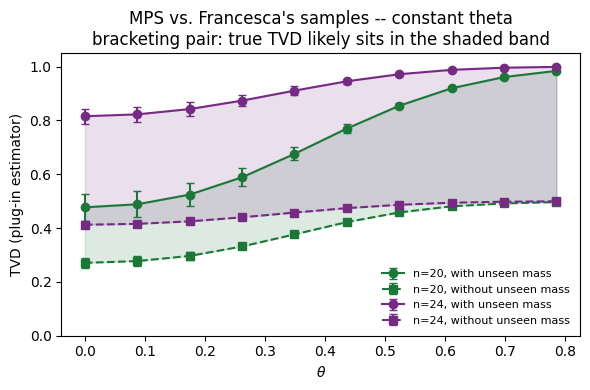

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
for n in (20, 24):
    thetas = sorted({theta for (nn, theta) in with_agg if nn == n})
    means_with = [with_agg[(n, t)][0] for t in thetas]
    stds_with = [with_agg[(n, t)][1] for t in thetas]
    means_without = [without_agg[(n, t)][0] for t in thetas]
    stds_without = [without_agg[(n, t)][1] for t in thetas]

    ax.errorbar(thetas, means_with, yerr=stds_with, marker="o", color=COLORS[n],
                linestyle="-", label=f"n={n}, with unseen mass", capsize=3)
    ax.errorbar(thetas, means_without, yerr=stds_without, marker="s", color=COLORS[n],
                linestyle="--", label=f"n={n}, without unseen mass", capsize=3)
    ax.fill_between(thetas, means_without, means_with, color=COLORS[n], alpha=0.15)

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("TVD (plug-in estimator)")
ax.set_title("MPS vs. Francesca's samples -- constant theta\nbracketing pair: true TVD likely sits in the shaded band")
ax.legend(frameon=False, fontsize=8)
ax.set_ylim(0, 1.05)
fig.tight_layout()
plt.show()


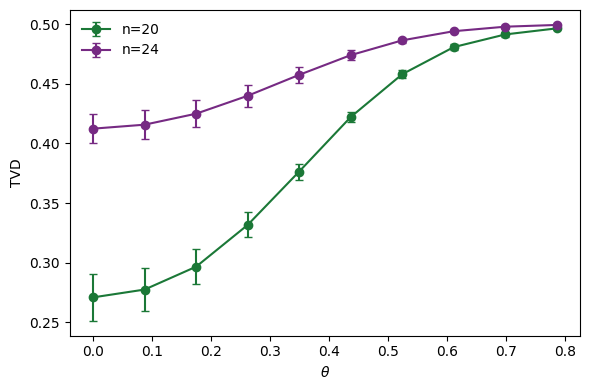

In [15]:
fig, ax = plt.subplots(figsize=(6, 4))
for n in (20, 24):
    thetas = sorted({theta for (nn, theta) in without_agg if nn == n})
    means = [without_agg[(n, t)][0] for t in thetas]
    stds = [without_agg[(n, t)][1] for t in thetas]
    ax.errorbar(thetas, means, yerr=stds, marker="o", color=COLORS[n], label=f"n={n}", capsize=3)

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("TVD")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### Aggregate & plot

(Colors fixed per system size across all figures below: n=20 green, n=24 purple -- never re-mapped.)

In [7]:
def aggregate(results, group_keys, metric="tvd"):
    groups = {}
    for r in results:
        key = tuple(r[k] for k in group_keys)
        groups.setdefault(key, []).append(r[metric])
    return {key: (np.mean(v), np.std(v)) for key, v in groups.items()}

const_agg = aggregate(const_results, ("n", "theta"), metric="tvd")
xeb_agg = aggregate(const_results, ("n", "theta"), metric="f_xeb")

for (n, theta), (mean, std) in sorted(const_agg.items()):
    print(f"n={n:3d} theta={theta:.4f}  TVD   = {mean:.3f} +/- {std:.3f}")
print()
for (n, theta), (mean, std) in sorted(xeb_agg.items()):
    print(f"n={n:3d} theta={theta:.4f}  F_XEB = {mean:.4f} +/- {std:.4f}")

n= 20 theta=0.0000  TVD   = 0.477 +/- 0.050
n= 20 theta=0.0873  TVD   = 0.488 +/- 0.048
n= 20 theta=0.1745  TVD   = 0.524 +/- 0.041
n= 20 theta=0.2618  TVD   = 0.589 +/- 0.033
n= 20 theta=0.3491  TVD   = 0.676 +/- 0.024
n= 20 theta=0.4363  TVD   = 0.770 +/- 0.017
n= 20 theta=0.5236  TVD   = 0.854 +/- 0.010
n= 20 theta=0.6109  TVD   = 0.920 +/- 0.006
n= 20 theta=0.6981  TVD   = 0.961 +/- 0.003
n= 20 theta=0.7854  TVD   = 0.984 +/- 0.001
n= 24 theta=0.0000  TVD   = 0.816 +/- 0.029
n= 24 theta=0.0873  TVD   = 0.823 +/- 0.028
n= 24 theta=0.1745  TVD   = 0.842 +/- 0.026
n= 24 theta=0.2618  TVD   = 0.874 +/- 0.022
n= 24 theta=0.3491  TVD   = 0.911 +/- 0.016
n= 24 theta=0.4363  TVD   = 0.945 +/- 0.010
n= 24 theta=0.5236  TVD   = 0.972 +/- 0.005
n= 24 theta=0.6109  TVD   = 0.988 +/- 0.002
n= 24 theta=0.6981  TVD   = 0.996 +/- 0.001
n= 24 theta=0.7854  TVD   = 0.999 +/- 0.000

n= 20 theta=0.0000  F_XEB = 1.0596 +/- 0.0789
n= 20 theta=0.0873  F_XEB = 1.0044 +/- 0.0534
n= 20 theta=0.1745  F_XEB =

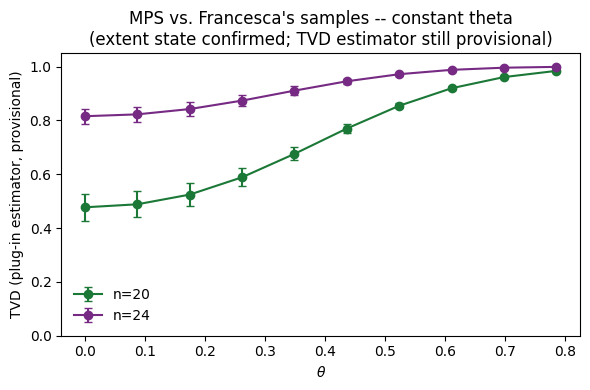

In [8]:
import matplotlib.pyplot as plt

COLORS = {20: "#1b7837", 24: "#762a83"}  # colorblind-safe, fixed per n, never re-mapped

fig, ax = plt.subplots(figsize=(6, 4))
for n in (20, 24):
    thetas = sorted({theta for (nn, theta) in const_agg if nn == n})
    means = [const_agg[(n, t)][0] for t in thetas]
    stds = [const_agg[(n, t)][1] for t in thetas]
    ax.errorbar(thetas, means, yerr=stds, marker="o", color=COLORS[n], label=f"n={n}", capsize=3)

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("TVD (plug-in estimator, provisional)")
ax.set_title("MPS vs. Francesca's samples -- constant theta\n(extent state confirmed; TVD estimator still provisional)")
ax.legend(frameon=False)
ax.set_ylim(0, 1.05)
fig.tight_layout()
plt.show()

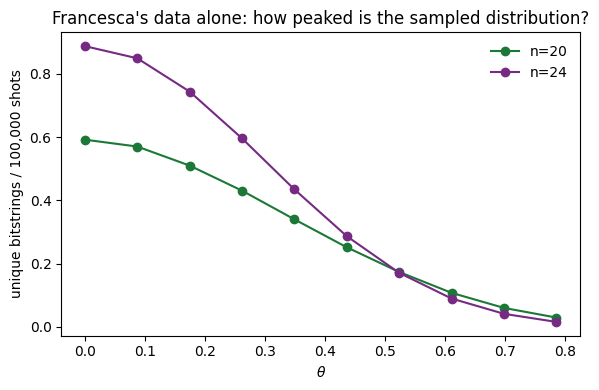

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
for n in (20, 24):
    thetas = sorted({r["theta"] for r in const_results if r["n"] == n})
    frac_by_theta = [np.mean([r["support_size"] / r["total_shots"]
                               for r in const_results if r["n"] == n and r["theta"] == t])
                      for t in thetas]
    ax.plot(thetas, frac_by_theta, marker="o", color=COLORS[n], label=f"n={n}")

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("unique bitstrings / 100,000 shots")
ax.set_title("Francesca's data alone: how peaked is the sampled distribution?")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

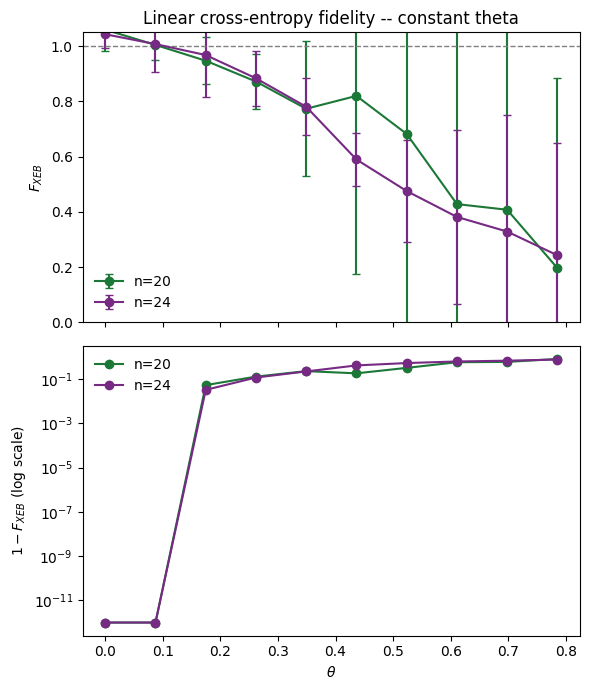

In [16]:
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(6, 7), sharex=True)

for n in (20, 24):
    thetas = sorted({theta for (nn, theta) in xeb_agg if nn == n})
    means = [xeb_agg[(n, t)][0] for t in thetas]
    stds = [xeb_agg[(n, t)][1] for t in thetas]
    ax0.errorbar(thetas, means, yerr=stds, marker="o", color=COLORS[n], label=f"n={n}", capsize=3)

ax0.axhline(1.0, color="gray", linewidth=1, linestyle="--")
ax0.set_ylabel(r"$F_{XEB}$")
ax0.set_title("Linear cross-entropy fidelity -- constant theta")
ax0.legend(frameon=False)
ax0.set_ylim(0, 1.05)

for n in (20, 24):
    thetas = sorted({theta for (nn, theta) in xeb_agg if nn == n})
    infid = [max(1 - xeb_agg[(n, t)][0], 1e-12) for t in thetas]
    ax1.plot(thetas, infid, marker="o", color=COLORS[n], label=f"n={n}")

ax1.set_yscale("log")
ax1.set_xlabel(r"$\theta$")
ax1.set_ylabel(r"$1-F_{XEB}$ (log scale)")
ax1.legend(frameon=False)

fig.tight_layout()
plt.show()

### What to look for once this runs

- **theta=0 check (the important one):** does $F_{XEB}$ land close to 1
  (equivalently $1-F_{XEB}$ close to 0, bottom panel) for both n=20 and n=24?
  If yes, that's real validation of the whole pipeline (circuit construction,
  bit convention, extent-state prep) -- much stronger evidence than the
  earlier "top-5 bitstrings roughly match" eyeball check, since it's now a
  single quantitative, low-variance number.
- **If it's not close to 1 at theta=0:** given both simulators are supposed to
  be exact there (pure Gaussian point), that would point to a real bug (bit
  order, site labeling, gate ordering) rather than an estimator artifact --
  unlike the TVD panel above, this metric shouldn't have a large non-zero
  floor at theta=0 by construction (its statistical error shrinks as
  $1/\sqrt N$ regardless of support size).
- **theta>0 trend:** however $F_{XEB}$ moves as theta grows now measures real
  behavior (genuine growing disagreement, or Francesca's own truncation error
  growing with the doping strength) rather than a mix of that plus a sampling
  artifact.

**Next action:** once this runs, if theta=0 looks good, send the $F_{XEB}$
curve to Francesca alongside the still-unconfirmed question of what error
metric she herself uses.

# Parallel sweep results (TVD without unseen mass + XEB, 4800 self-overlap samples)

Loads `const_sweep_results.pkl`, produced by `run_xeb_sweep.py` /
`xeb_sweep_worker.py` running outside this notebook (10 parallel single-threaded
workers, one per `(n, theta, seed)` file). If that sweep hasn't finished yet,
this just reflects however many of the 100 points are saved so far -- re-run
once it's complete for the full picture.

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

COLORS = {20: "#1b7837", 24: "#762a83"}  # colorblind-safe, fixed per n

In [2]:
with open("const_sweep_results.pkl", "rb") as f:
    sweep_results = pickle.load(f)
print(f"{len(sweep_results)}/100 points loaded")

def aggregate_sweep(results, metric):
    groups = {}
    for r in results:
        groups.setdefault((r["n"], r["theta"]), []).append(r[metric])
    return {key: (np.mean(v), np.std(v)) for key, v in groups.items()}

sweep_tvd_agg = aggregate_sweep(sweep_results, "tvd")
sweep_xeb_agg = aggregate_sweep(sweep_results, "f_xeb")

100/100 points loaded


[0.2707876680176988, 0.27735810723297893, 0.29655465673138426, 0.3315964837007437, 0.376439040479015, 0.4221655888593306, 0.4581075668445333, 0.4808668441247665, 0.49150444575427504, 0.49659138045567247]
[0.019752798828772587, 0.018167162572011297, 0.014870710831264287, 0.010472952418204211, 0.006706484661739161, 0.004160091648336604, 0.0034891774661183913, 0.0024998794411554806, 0.001770815198295947, 0.0008233381434974998]
[0.41240294256915355, 0.41574421126715694, 0.42496845007592804, 0.4399977478134044, 0.4575775438831357, 0.4741136354888715, 0.48652645032705255, 0.4942064858303931, 0.4979951534060481, 0.49946617386727654]
[0.012319174311430788, 0.012121359594560345, 0.011383867822385672, 0.00942946528930801, 0.006789341581119851, 0.0040868854824908886, 0.0021404793507576203, 0.0010279931241786897, 0.00039653550204009645, 0.00010892915562436498]


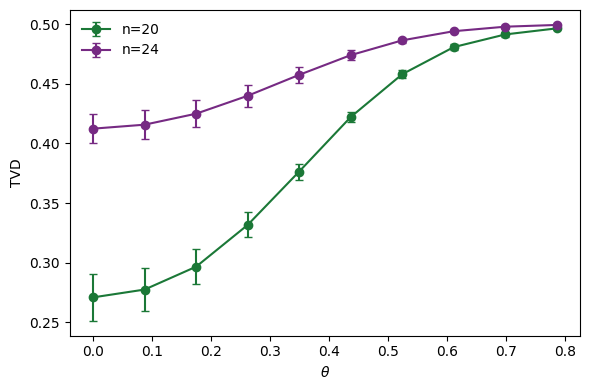

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
for n in (20, 24):
    thetas = sorted({theta for (nn, theta) in sweep_tvd_agg if nn == n})
    means = [sweep_tvd_agg[(n, t)][0] for t in thetas]
    stds = [sweep_tvd_agg[(n, t)][1] for t in thetas]
    print(means)
    print(stds)
    ax.errorbar(thetas, means, yerr=stds, marker="o", color=COLORS[n], label=f"n={n}", capsize=3)

ax.set_xlabel(r"$\theta$")
ax.set_ylabel("TVD")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [ ]:
# save mean and std of 20 and 24 qubits for TVD in a .csv file


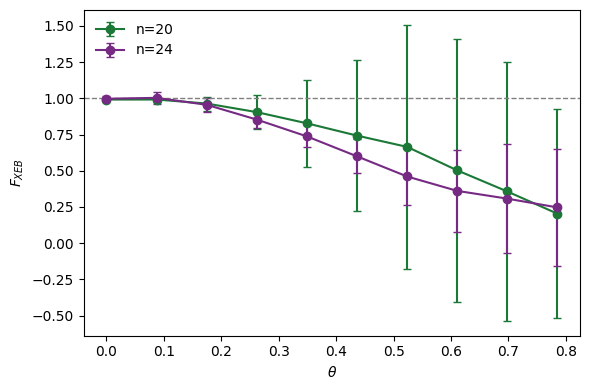

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
for n in (20, 24):
    thetas = sorted({theta for (nn, theta) in sweep_xeb_agg if nn == n})
    means = [sweep_xeb_agg[(n, t)][0] for t in thetas]
    stds = [sweep_xeb_agg[(n, t)][1] for t in thetas]
    ax.errorbar(thetas, means, yerr=stds, marker="o", color=COLORS[n], label=f"n={n}", capsize=3)

ax.axhline(1.0, color="gray", linewidth=1, linestyle="--")
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$F_{XEB}$")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Seed-by-seed breakdown of F_XEB

Same `sweep_results` data as above, grouped by seed instead of averaged across seeds -- this is exactly the split used in the chat diagnostic that showed the large error bars at high theta come from real seed-to-seed variability, not Monte Carlo noise in the self-overlap estimate.

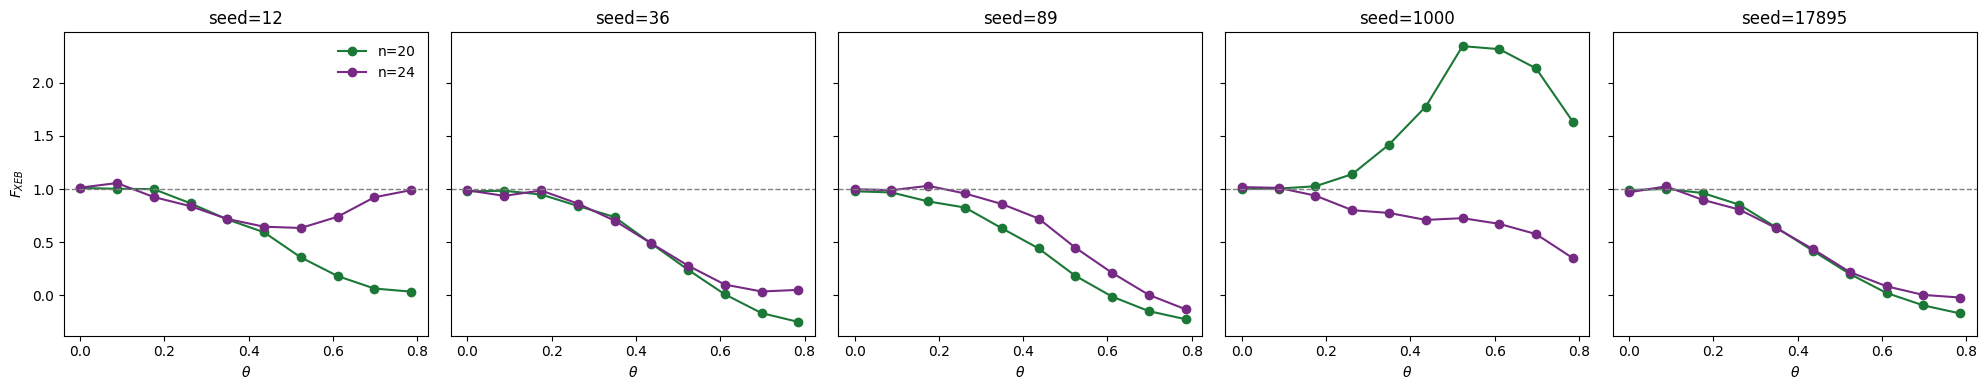

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
seeds = sorted({r["seed"] for r in sweep_results})

for ax, seed in zip(axes, seeds):
    for n in (20, 24):
        pts = sorted((r["theta"], r["f_xeb"]) for r in sweep_results
                     if r["seed"] == seed and r["n"] == n)
        thetas = [p[0] for p in pts]
        vals = [p[1] for p in pts]
        ax.plot(thetas, vals, marker="o", color=COLORS[n], label=f"n={n}")
    ax.axhline(1.0, color="gray", linewidth=1, linestyle="--")
    ax.set_title(f"seed={seed}")
    ax.set_xlabel(r"$\theta$")

axes[0].set_ylabel(r"$F_{XEB}$")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

## Seed-by-seed breakdown of TVD

Same idea as the F_XEB breakdown above, but for TVD (without unseen mass) -- checking whether the same seed-to-seed divergence at high theta shows up here too, or whether it's peculiar to the XEB fidelity.

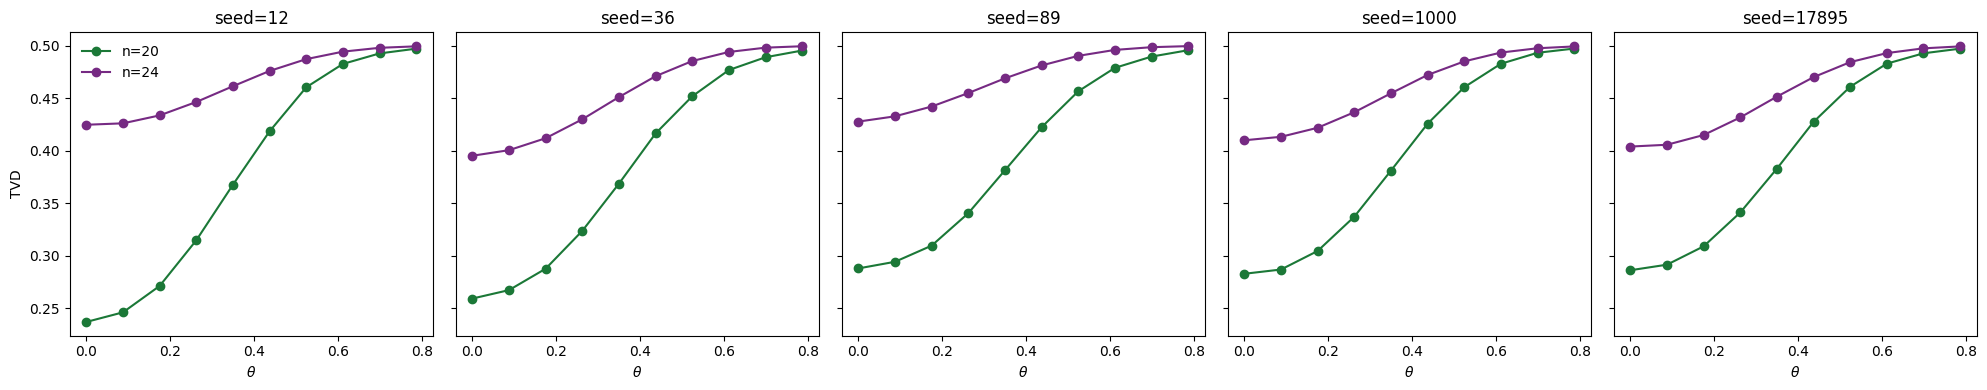

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
seeds = sorted({r["seed"] for r in sweep_results})

for ax, seed in zip(axes, seeds):
    for n in (20, 24):
        pts = sorted((r["theta"], r["tvd"]) for r in sweep_results
                     if r["seed"] == seed and r["n"] == n)
        thetas = [p[0] for p in pts]
        vals = [p[1] for p in pts]
        ax.plot(thetas, vals, marker="o", color=COLORS[n], label=f"n={n}")
    ax.set_title(f"seed={seed}")
    ax.set_xlabel(r"$\theta$")

axes[0].set_ylabel("TVD")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()